# RetailRocket — Raw EDA

Mục tiêu: đánh giá hành vi visitor từ view → add-to-cart → transaction. Timestamp
gốc là Unix milliseconds và được chuyển rõ ràng sang Datetime.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import polars as pl

project_root = Path.cwd().resolve()
while project_root.parent != project_root and not (project_root / "src").exists():
    project_root = project_root.parent
if not (project_root / "src").exists():
    raise RuntimeError("Không tìm thấy project root chứa thư mục src")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.eda.config import DatasetSpec
from src.eda.descriptive import (
    describe_dataset,
    describe_entities,
    describe_quality,
    describe_temporal,
)
from src.eda.visualization import (
    plot_active_periods_per_entity,
    plot_entity_time_matrix,
    plot_missing_values,
    plot_records_over_time,
    plot_records_per_entity,
)

data_dir = project_root / "data" / "raw" / "retail"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(20)

def scalar_metrics(report):
    return {key: value for key, value in report.items() if not isinstance(value, pl.DataFrame)}

## 1. Load và chuẩn hóa bảng sự kiện

In [3]:
events = (
    pl.scan_csv(data_dir / "events.csv")
    .with_columns(
        pl.from_epoch(pl.col("timestamp"), time_unit="ms").alias("event_time")
    )
)
spec = DatasetSpec(
    name="retailrocket_events",
    entity_col="visitorid",
    time_col="event_time",
    categorical_cols=("event",),
    id_cols=("itemid", "transactionid"),
)

## 2. Dataset overview

In [4]:
dataset_report = describe_dataset(events, spec)
print("Shape:", dataset_report["n_rows"], "rows x", dataset_report["n_cols"], "columns")
print("Dtype groups:", dataset_report["dtype_groups"])
display(dataset_report["overview"].sort("missing_frac", descending=True))
display(dataset_report["preview"])

Shape: 2756101 rows x 6 columns
Dtype groups: {'numeric': ['timestamp', 'visitorid', 'itemid'], 'string': ['event', 'transactionid'], 'categorical': [], 'temporal': ['event_time'], 'boolean': [], 'other': []}


column,dtype,n_missing,missing_frac,n_unique_approx
str,str,i64,f64,i64
"""transactionid""","""String""",2733644,0.991852,17304
"""timestamp""","""Int64""",0,0.0,2745181
"""visitorid""","""Int64""",0,0.0,1294939
"""event""","""String""",0,0.0,3
"""itemid""","""Int64""",0,0.0,237288
"""event_time""","""Datetime(time_unit='us', time_…",0,0.0,2594979


timestamp,visitorid,event,itemid,transactionid,event_time
i64,i64,str,i64,str,datetime[μs]
1433221332117,257597,"""view""",355908,null,2015-06-02 05:02:12.117
1433224214164,992329,"""view""",248676,null,2015-06-02 05:50:14.164
1433221999827,111016,"""view""",318965,null,2015-06-02 05:13:19.827
1433221955914,483717,"""view""",253185,null,2015-06-02 05:12:35.914
1433221337106,951259,"""view""",367447,null,2015-06-02 05:02:17.106


## 3. Data quality

In [5]:
quality_report = describe_quality(events, spec)
print(scalar_metrics(quality_report))
display(quality_report["column_quality"].sort("missing_pct", descending=True))

{'n_rows': 2756101, 'n_cols': 6, 'n_duplicate_rows': 460, 'duplicate_row_pct': 0.016690244660845156, 'n_missing_cells': 2733644, 'missing_cell_pct': 16.530864918714276, 'n_columns_with_missing': 1, 'constant_columns': [], 'all_missing_columns': []}


column,dtype,n_missing,missing_pct,n_unique_non_missing,is_constant,is_all_missing
str,str,i64,f64,i64,bool,bool
"""transactionid""","""String""",2733644,99.18519,17672,false,false
"""timestamp""","""Int64""",0,0.0,2750455,false,false
"""visitorid""","""Int64""",0,0.0,1407580,false,false
"""event""","""String""",0,0.0,3,false,false
"""itemid""","""Int64""",0,0.0,235061,false,false
"""event_time""","""Datetime(time_unit='us', time_…",0,0.0,2750455,false,false


## 4. Temporal coverage

{'time_col': 'event_time', 'n_records': 2756101, 'n_valid_time': 2756101, 'n_missing_or_invalid_time': 0, 'start_date': datetime.date(2015, 5, 3), 'end_date': datetime.date(2015, 9, 18), 'history_months': 5, 'observed_months': 5, 'missing_months': [], 'mean_records_per_month': 551220.2, 'std_records_per_month': 132560.76833875096, 'monthly_count_cv': 0.24048604956558373, 'min_records_per_month': 303710, 'max_records_per_month': 697984}


month,n_records
date,u32
2015-05-01,590652
2015-06-01,610393
2015-07-01,697984
2015-08-01,553362
2015-09-01,303710


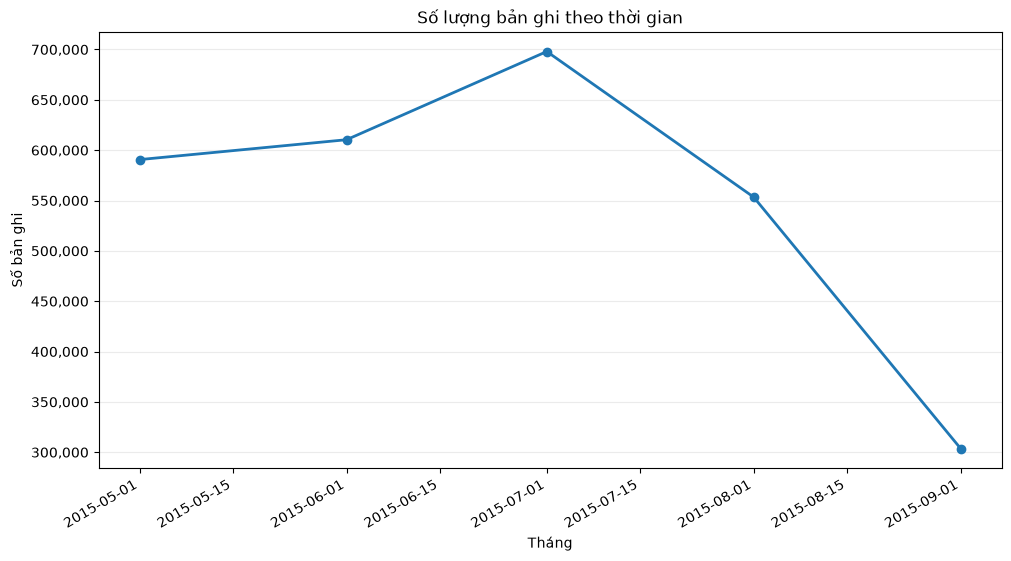

In [6]:
temporal_report = describe_temporal(events, spec)
print(scalar_metrics(temporal_report))
display(temporal_report["monthly_records"])

plot_records_over_time(temporal_report["monthly_records"])
plt.show()

## 5. Entity history

{'entity_col': 'visitorid', 'n_unique_entities': 1407580, 'n_records_missing_entity': 0, 'n_repeat_entities': 406020, 'repeat_entity_pct': 28.845252134869778, 'avg_records_per_entity': 1.9580421716705267, 'n_entities_active_2plus_months': 65602, 'active_2plus_months_pct': 4.660623197260547, 'min_history_days': 0, 'min_history_days_gt_0': 1, 'mean_history_days': 2.375353443498771, 'median_history_days': 0.0, 'max_history_days': 138}


visitorid,n_records,n_active_months,first_seen,last_seen,history_days
i64,u32,u32,date,date,i64
0,3,1,2015-09-11,2015-09-11,0
1,1,1,2015-08-13,2015-08-13,0
2,8,1,2015-08-07,2015-08-07,0
3,1,1,2015-08-01,2015-08-01,0
4,1,1,2015-09-15,2015-09-15,0
5,1,1,2015-07-17,2015-07-17,0
6,6,1,2015-08-30,2015-08-31,1
7,3,1,2015-05-14,2015-05-16,2
8,1,1,2015-05-31,2015-05-31,0


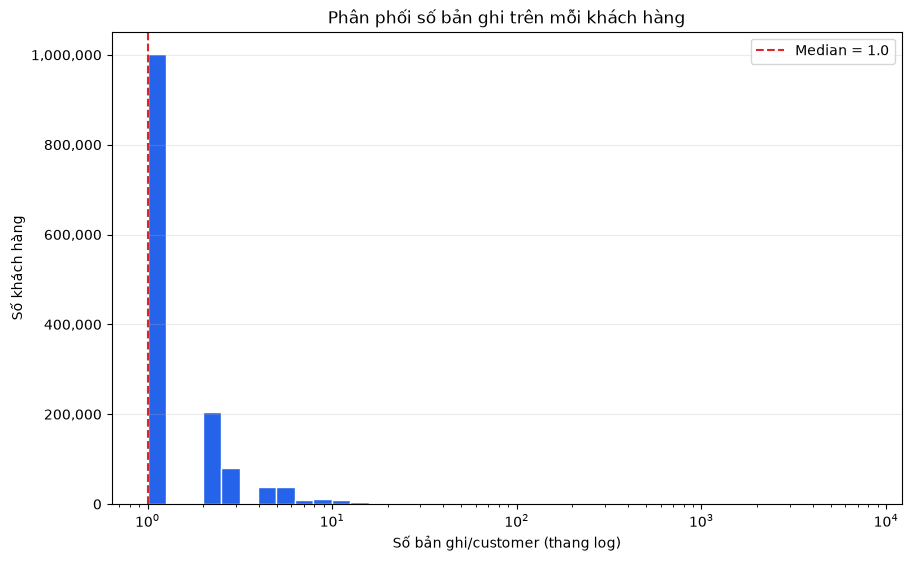

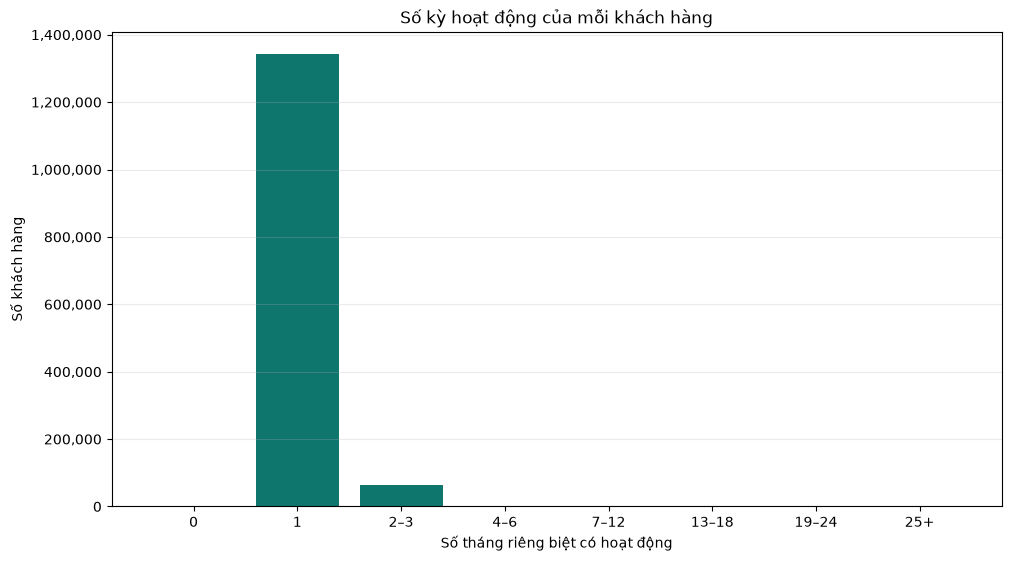

In [7]:
entity_report = describe_entities(events, spec)
print(scalar_metrics(entity_report))
display(entity_report["entity_history"].head(20))

plot_records_per_entity(entity_report["entity_history"])
plt.show()
plot_active_periods_per_entity(entity_report["entity_history"])
plt.show()

## 6. Missing values

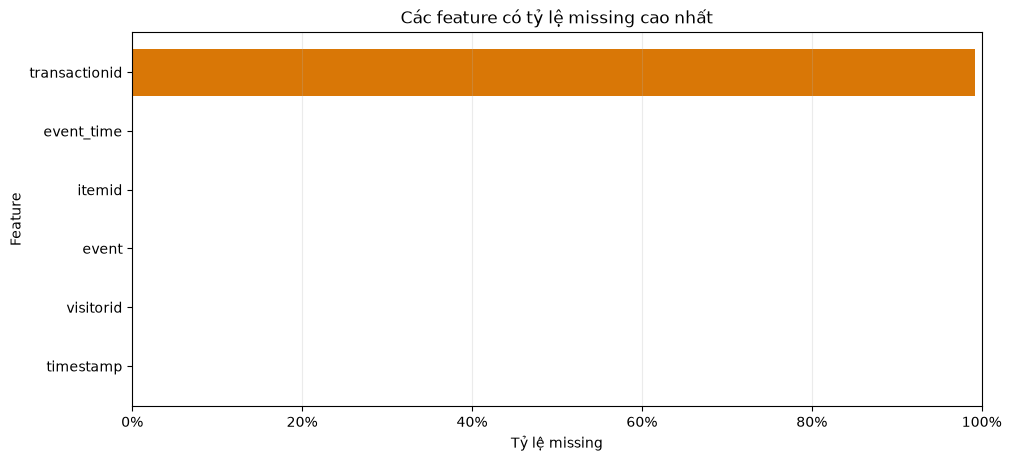

In [8]:
plot_missing_values(quality_report["column_quality"], top_n=20)
plt.show()

## 7. Customer activity matrix

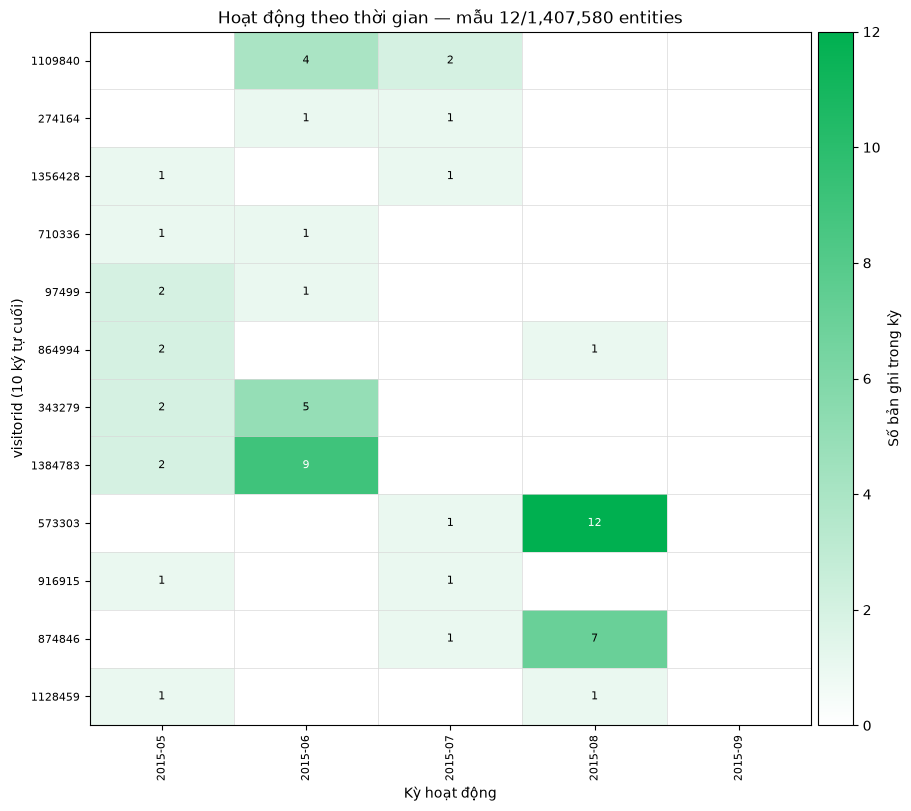

visitorid,2015-05,2015-06,2015-07,2015-08,2015-09
i64,i64,i64,i64,i64,i64
1109840,0,4,2,0,0
274164,0,1,1,0,0
1356428,1,0,1,0,0
710336,1,1,0,0,0
97499,2,1,0,0,0
864994,2,0,0,1,0
343279,2,5,0,0,0
1384783,2,9,0,0,0
573303,0,0,1,12,0


visitorid,active_periods,total_periods,coverage_pct,total_records
i64,u32,i32,f64,u32
1109840,2,5,40.0,6
864994,2,5,40.0,3
1356428,2,5,40.0,2
573303,2,5,40.0,13
343279,2,5,40.0,7
97499,2,5,40.0,3
874846,2,5,40.0,8
1384783,2,5,40.0,11
1128459,2,5,40.0,2


Global coverage: ActivityCoverage(n_entities=1407580, n_eligible_entities=65602, n_periods=5, n_active_entity_periods=1483461, coverage_pct=21.078176728853776, sample_size=12)


In [9]:
matrix_result = plot_entity_time_matrix(
    events,
    entity_col=spec.entity_col,
    timestamp_col=spec.time_col,
    sample_size=12,
    min_active_periods=2,
    seed=42,
    id_suffix=10,
    annotate=True,
)
plt.show()
display(matrix_result.matrix)
display(matrix_result.entity_coverage)
print("Global coverage:", matrix_result.global_coverage)

## 8. Dataset-specific signals

In [10]:
event_distribution = (
    events.group_by("event")
    .agg(pl.len().alias("n_events"))
    .with_columns((100 * pl.col("n_events") / pl.col("n_events").sum()).alias("pct"))
    .sort("n_events", descending=True)
    .collect()
)
display(event_distribution)

funnel_entities = (
    events.group_by("event")
    .agg(pl.col("visitorid").n_unique().alias("n_unique_visitors"))
    .sort("n_unique_visitors", descending=True)
    .collect()
)
display(funnel_entities)

category_tree = pl.scan_csv(data_dir / "category_tree.csv")
properties_1 = pl.scan_csv(data_dir / "item_properties_part1.csv")
properties_2 = pl.scan_csv(data_dir / "item_properties_part2.csv")
print("Category schema:", category_tree.collect_schema())
print("Item property schema:", properties_1.collect_schema())
display(category_tree.head(5).collect())
display(properties_2.head(5).collect())

event,n_events,pct
str,u32,f64
"""view""",2664312,96.669607
"""addtocart""",69332,2.515583
"""transaction""",22457,0.81481


event,n_unique_visitors
str,u32
"""view""",1404179
"""addtocart""",37722
"""transaction""",11719


Category schema: Schema([('categoryid', Int64), ('parentid', Int64)])
Item property schema: Schema([('timestamp', Int64), ('itemid', Int64), ('property', String), ('value', String)])


categoryid,parentid
i64,i64
1016,213
809,169
570,9
1691,885
536,1691


timestamp,itemid,property,value
i64,i64,str,str
1433041200000,183478,"""561""","""769062"""
1439694000000,132256,"""976""","""n26.400 1135780"""
1435460400000,420307,"""921""","""1149317 1257525"""
1431831600000,403324,"""917""","""1204143"""
1435460400000,230701,"""521""","""769062"""


## 9. Slide selection summary

Dataset có funnel hành vi rõ và phù hợp propensity-to-buy. Chưa có label tại
snapshot; có thể tạo target “phát sinh transaction trong N ngày tiếp theo”.

In [11]:
slide_summary = pl.DataFrame(
    {
        "dataset": ["RetailRocket"],
        "n_rows": [dataset_report["n_rows"]],
        "n_columns": [dataset_report["n_cols"]],
        "n_entities": [entity_report["n_unique_entities"]],
        "history_months": [temporal_report["history_months"]],
        "missing_months": [len(temporal_report["missing_months"])],
        "repeat_entity_pct": [entity_report["repeat_entity_pct"]],
        "active_2plus_months_pct": [entity_report["active_2plus_months_pct"]],
        "missing_cell_pct": [quality_report["missing_cell_pct"]],
        "duplicate_row_pct": [quality_report["duplicate_row_pct"]],
        "target_status": ["Cần tạo future transaction label"],
    }
)
display(slide_summary)

dataset,n_rows,n_columns,n_entities,history_months,missing_months,repeat_entity_pct,active_2plus_months_pct,missing_cell_pct,duplicate_row_pct,target_status
str,i64,i64,i64,i64,i64,f64,f64,f64,f64,str
"""RetailRocket""",2756101,6,1407580,5,0,28.845252,4.660623,16.530865,0.01669,"""Cần tạo future transaction lab…"
